# Sistema predictivo de recomendación de cultivos para la optimización agrícola
## Tercera Entrega: Selección de Características y Reducción de Dimensionalidad (PCA y UMAP)

**Integrantes:**
- Jonatan Romero (`jonatan.romeroa@udea.edu.co`)
- Sebastian Berrio (`sebastian.berriom@udea.edu.co`)
- Cristian Diez (`cristian.diez@udea.edu.co`)

*Ingeniería de Sistemas — Universidad de Antioquia*

---

### 1. Configuración del entorno y librerías

Se importan las librerías para el análisis de importancia de variables, reducción de dimensionalidad lineal con `PCA` y no lineal con `UMAP` (`umap-learn`), junto con los clasificadores y métricas de `scikit-learn`.

Se mantiene fija la semilla `random_state=42` en todos los procedimientos para conservar la misma partición de datos y asegurar la reproducibilidad respecto a los experimentos del Notebook 02.

In [1]:
from pathlib import Path
from typing import Any
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import umap

warnings.filterwarnings("ignore")
RANDOM_STATE: int = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.precision", 4)

### 2. Carga de datos, partición estratificada y definición de los mejores modelos

Se carga el archivo `data/Crop_recommendation.csv` (2200 muestras, 7 variables numéricas y 22 cultivos balanceados) y se aplica la misma partición estratificada 80/20 (`test_size=0.2, random_state=42, stratify=y`) utilizada en el Notebook 02, obteniendo 1760 muestras de entrenamiento y 440 de prueba.

A partir de los resultados del Notebook 02, se seleccionan los dos modelos con mayor `F1 Macro` y `Accuracy` en el conjunto de prueba: **Perceptrón Multicapa (MLP)** con `hidden_layer_sizes=(32,), alpha=0.01` (`F1 Macro = 0.9932`) y **Support Vector Machine (SVM RBF)** con `C=1, gamma=1` (`F1 Macro = 0.9909`), registrando además la línea base de los cinco clasificadores originales para la comparación final.

In [2]:
ruta_dataset = Path("data/Crop_recommendation.csv")
if not ruta_dataset.exists():
    ruta_dataset = Path("../data/Crop_recommendation.csv")

df = pd.read_csv(ruta_dataset)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df = df.rename(columns={"Nitrogen": "N", "phosphorus": "P", "potassium": "K"})

columnas_predictoras: list[str] = [
    "N",
    "P",
    "K",
    "temperature",
    "humidity",
    "ph",
    "rainfall",
]

X: pd.DataFrame = df[columnas_predictoras].copy()
y: pd.Series = df["label"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


def crear_mejores_modelos() -> dict[str, Any]:
    return {
        "Perceptrón Multicapa (MLP)": MLPClassifier(
            hidden_layer_sizes=(32,),
            alpha=0.01,
            max_iter=500,
            random_state=RANDOM_STATE,
        ),
        "Support Vector Machine (SVM RBF)": SVC(
            kernel="rbf",
            C=1,
            gamma=1,
            probability=True,
            random_state=RANDOM_STATE,
        ),
    }


def evaluar_en_espacio(
    enfoque_nombre: str,
    dimension_texto: str,
    modelo: Any,
    X_tr: np.ndarray,
    X_te: np.ndarray,
) -> dict[str, Any]:
    modelo.fit(X_tr, y_train)
    y_pred = modelo.predict(X_te)
    acc = float(accuracy_score(y_test, y_pred))
    return {
        "Enfoque / Modelo": enfoque_nombre,
        "Dimensión Original/Reducida": dimension_texto,
        "Accuracy": acc,
        "Error de Clasificación": 1.0 - acc,
        "Precision Macro": float(
            precision_score(y_test, y_pred, average="macro", zero_division=0)
        ),
        "Recall Macro": float(
            recall_score(y_test, y_pred, average="macro", zero_division=0)
        ),
        "F1 Macro": float(
            f1_score(y_test, y_pred, average="macro", zero_division=0)
        ),
    }


resultados_base_nb02: list[dict[str, Any]] = [
    {
        "Enfoque / Modelo": "Base: Perceptrón Multicapa (MLP)",
        "Dimensión Original/Reducida": "Original (7 variables)",
        "Accuracy": 0.9932,
        "Error de Clasificación": 0.0068,
        "Precision Macro": 0.9937,
        "Recall Macro": 0.9932,
        "F1 Macro": 0.9932,
    },
    {
        "Enfoque / Modelo": "Base: Support Vector Machine (SVM RBF)",
        "Dimensión Original/Reducida": "Original (7 variables)",
        "Accuracy": 0.9909,
        "Error de Clasificación": 0.0091,
        "Precision Macro": 0.9915,
        "Recall Macro": 0.9909,
        "F1 Macro": 0.9909,
    },
    {
        "Enfoque / Modelo": "Base: Random Forest",
        "Dimensión Original/Reducida": "Original (7 variables)",
        "Accuracy": 0.9886,
        "Error de Clasificación": 0.0114,
        "Precision Macro": 0.9897,
        "Recall Macro": 0.9886,
        "F1 Macro": 0.9887,
    },
    {
        "Enfoque / Modelo": "Base: Regresión Logística",
        "Dimensión Original/Reducida": "Original (7 variables)",
        "Accuracy": 0.9841,
        "Error de Clasificación": 0.0159,
        "Precision Macro": 0.9852,
        "Recall Macro": 0.9841,
        "F1 Macro": 0.9840,
    },
    {
        "Enfoque / Modelo": "Base: K-Nearest Neighbors (KNN)",
        "Dimensión Original/Reducida": "Original (7 variables)",
        "Accuracy": 0.9727,
        "Error de Clasificación": 0.0273,
        "Precision Macro": 0.9746,
        "Recall Macro": 0.9727,
        "F1 Macro": 0.9725,
    },
]

display(pd.DataFrame(resultados_base_nb02).head(2))

,Enfoque / Modelo,Dimensión Original/Reducida,Accuracy,Error de Clasificación,Precision Macro,Recall Macro,F1 Macro
0,Base: Perceptrón Multicapa (MLP),Original (7 variables),0.9932,0.0068,0.9937,0.9932,0.9932
1,Base: Support Vector Machine (SVM RBF),Original (7 variables),0.9909,0.0091,0.9915,0.9909,0.9909


### 3. Análisis individual de características mediante Random Forest (Etapa 10)

Para medir el aporte de cada variable en la separación de los 22 cultivos, se extrae la importancia de características (*Feature Importance*) con el modelo Random Forest optimizado (`n_estimators=19, max_depth=10, max_features='sqrt'`), que cuantifica la reducción media de la impureza de Gini ($\Delta i(t)$) en los nodos de división.

El gráfico de barras horizontal muestra que `rainfall` (20.41%), `humidity` (20.33%), `K` (19.57%) y `P` (17.02%) concentran el 77.33% de la importancia total, mientras que `N` (9.34%), `temperature` (8.23%) y `ph` (5.10%) tienen menor peso individual por el solapamiento de sus rangos entre cultivos.

,Variable,Importancia (Gini),Importancia (%)
0,rainfall,0.2041,20.4096
1,humidity,0.2033,20.3274
2,K,0.1957,19.5735
3,P,0.1702,17.0169
4,N,0.0934,9.3405
5,temperature,0.0823,8.2338
6,ph,0.0510,5.0982


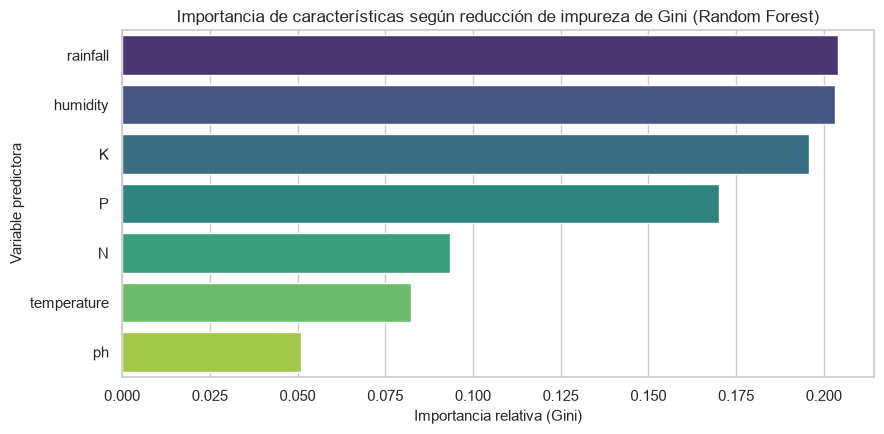

In [3]:
rf_importancia = RandomForestClassifier(
    n_estimators=19,
    max_depth=10,
    max_features="sqrt",
    random_state=RANDOM_STATE,
)
rf_importancia.fit(X_train, y_train)

df_importancia = (
    pd.DataFrame(
        {
            "Variable": columnas_predictoras,
            "Importancia (Gini)": rf_importancia.feature_importances_,
            "Importancia (%)": rf_importancia.feature_importances_ * 100,
        }
    )
    .sort_values(by="Importancia (Gini)", ascending=False)
    .reset_index(drop=True)
)
display(df_importancia)

plt.figure(figsize=(9, 4.5))
sns.barplot(
    data=df_importancia,
    x="Importancia (Gini)",
    y="Variable",
    hue="Variable",
    palette="viridis",
    legend=False,
)
plt.title("Importancia de características según reducción de impureza de Gini (Random Forest)", fontsize=12)
plt.xlabel("Importancia relativa (Gini)", fontsize=11)
plt.ylabel("Variable predictora", fontsize=11)
plt.tight_layout()
plt.show()

### 4. Análisis de Componentes Principales - PCA y varianza explicada (Etapa 11)

El Análisis de Componentes Principales (PCA) realiza una proyección ortogonal lineal $\mathbf{Z} = \mathbf{X}\mathbf{W}$ sobre los vectores propios de la matriz de covarianza de los datos estandarizados, maximizando la varianza retenida en direcciones mutuamente ortogonales y eliminando la colinealidad observada entre `P` y `K` ($r = 0.74$).

Al ajustar `PCA` sobre el conjunto de entrenamiento estandarizado, las primeras **6 componentes principales** explican el **97.24%** de la varianza total (superando el umbral del 90% y 95%), mientras que la séptima componente (`PC7`) concentra únicamente el **2.76%** restante asociado a la redundancia lineal.

,Componente,Varianza Explicada,Varianza Acumulada,Varianza Acumulada (%)
0,PC1,0.2738,0.2738,27.3837
1,PC2,0.1867,0.4605,46.0526
2,PC3,0.1531,0.6136,61.3579
3,PC4,0.1461,0.7597,75.9673
4,PC5,0.1144,0.8740,87.4046
5,PC6,0.0984,0.9724,97.2401
6,PC7,0.0276,1.0000,100.0000


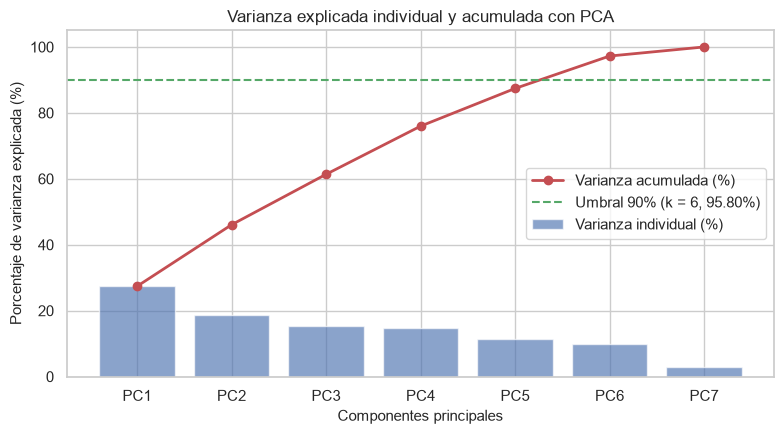

In [4]:
pca_completo = PCA(random_state=RANDOM_STATE)
pca_completo.fit(X_train_scaled)

varianza_individual = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

df_varianza_pca = pd.DataFrame(
    {
        "Componente": [f"PC{i + 1}" for i in range(len(columnas_predictoras))],
        "Varianza Explicada": varianza_individual,
        "Varianza Acumulada": varianza_acumulada,
        "Varianza Acumulada (%)": varianza_acumulada * 100,
    }
)
display(df_varianza_pca)

n_componentes_pca = int(np.argmax(varianza_acumulada >= 0.90) + 1)

plt.figure(figsize=(8, 4.5))
indices = np.arange(1, len(columnas_predictoras) + 1)
plt.bar(indices, varianza_individual * 100, alpha=0.65, color="#4C72B0", label="Varianza individual (%)")
plt.plot(indices, varianza_acumulada * 100, marker="o", color="#C44E52", linewidth=2, label="Varianza acumulada (%)")
plt.axhline(y=90, color="#55A868", linestyle="--", label=f"Umbral 90% (k = {n_componentes_pca}, {varianza_acumulada[n_componentes_pca - 1] * 100:.2f}%)")
plt.xticks(indices, [f"PC{i}" for i in indices])
plt.ylabel("Porcentaje de varianza explicada (%)", fontsize=11)
plt.xlabel("Componentes principales", fontsize=11)
plt.title("Varianza explicada individual y acumulada con PCA", fontsize=12)
plt.ylim(0, 105)
plt.legend(loc="center right")
plt.tight_layout()
plt.show()

### 5. Proyección 2D (PC1 vs PC2) y evaluación de los mejores modelos con PCA (Etapa 12)

Se grafica la dispersión de las clases en las dos primeras componentes principales (`PC1` con 27.38% y `PC2` con 18.67%, acumulando el 46.05% de la varianza). Aunque se separan cultivos con niveles extremos de potasio y fósforo (como manzana y uva), dos dimensiones lineales resultan insuficientes para desacoplar las 22 clases sin solapamiento.

Al entrenar los dos mejores modelos empleando las $k = 6$ componentes principales (97.24% de varianza), **MLP + PCA** alcanza un `Accuracy` de `0.9886` (`F1 Macro = 0.9886`) y **SVM RBF + PCA** obtiene un `Accuracy` de `0.9841` (`F1 Macro = 0.9840`), reduciendo una dimensión con una variación menor a 0.7 puntos porcentuales respecto al espacio original.

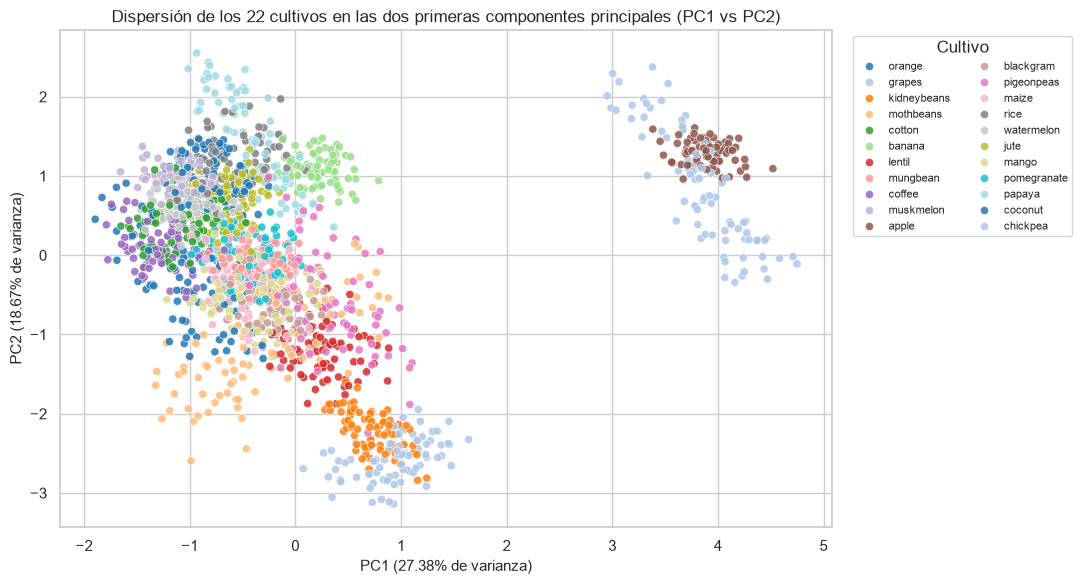

,Enfoque / Modelo,Dimensión Original/Reducida,Accuracy,Error de Clasificación,Precision Macro,Recall Macro,F1 Macro
0,PCA: Perceptrón Multicapa (MLP),Reducida (6 componentes PCA),0.9886,0.0114,0.9889,0.9886,0.9886
1,PCA: Support Vector Machine (SVM RBF),Reducida (6 componentes PCA),0.9841,0.0159,0.9847,0.9841,0.9840


In [5]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca_2d = pca_2d.fit_transform(X_train_scaled)

df_pca_2d = pd.DataFrame(X_train_pca_2d, columns=["PC1", "PC2"])
df_pca_2d["Cultivo"] = y_train.values

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_pca_2d,
    x="PC1",
    y="PC2",
    hue="Cultivo",
    palette="tab20",
    s=35,
    alpha=0.85,
)
plt.title("Dispersión de los 22 cultivos en las dos primeras componentes principales (PC1 vs PC2)", fontsize=12)
plt.xlabel(f"PC1 ({varianza_individual[0] * 100:.2f}% de varianza)", fontsize=11)
plt.ylabel(f"PC2 ({varianza_individual[1] * 100:.2f}% de varianza)", fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8, title="Cultivo")
plt.tight_layout()
plt.show()

pca_optimo = PCA(n_components=n_componentes_pca, random_state=RANDOM_STATE)
X_train_pca = pca_optimo.fit_transform(X_train_scaled)
X_test_pca = pca_optimo.transform(X_test_scaled)

resultados_pca: list[dict[str, Any]] = []
for nombre, modelo in crear_mejores_modelos().items():
    resultados_pca.append(
        evaluar_en_espacio(
            enfoque_nombre=f"PCA: {nombre}",
            dimension_texto=f"Reducida ({n_componentes_pca} componentes PCA)",
            modelo=modelo,
            X_tr=X_train_pca,
            X_te=X_test_pca,
        )
    )

df_resultados_pca = pd.DataFrame(resultados_pca)
display(df_resultados_pca)

### 6. Reducción de dimensionalidad no lineal con UMAP y visualización 2D (Etapa 13)

Uniform Manifold Approximation and Projection (UMAP) es un método de reducción de dimensionalidad no lineal fundamentado en geometría riemanniana y topología algebraica. El algoritmo asume que los datos se encuentran sobre una variedad diferenciable (*manifold*) local y construye un grafo difuso ponderado en el espacio original ($\mathbb{R}^7$) a partir de los $n_{\text{neighbors}} = 15$ vecinos más cercanos, para luego optimizar una representación en baja dimensión ($\mathbb{R}^2$) minimizando la entropía cruzada difusa entre ambas estructuras topológicas con una distancia mínima `min_dist=0.1`.

Al ajustar `UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)` sobre `X_train_scaled` y graficar el plano bidimensional resultante, se aprecia cómo UMAP desenreda las relaciones no lineales entre nutrientes y clima, formando islas compactas y bien separadas para la mayoría de los 22 cultivos con solo 2 dimensiones.

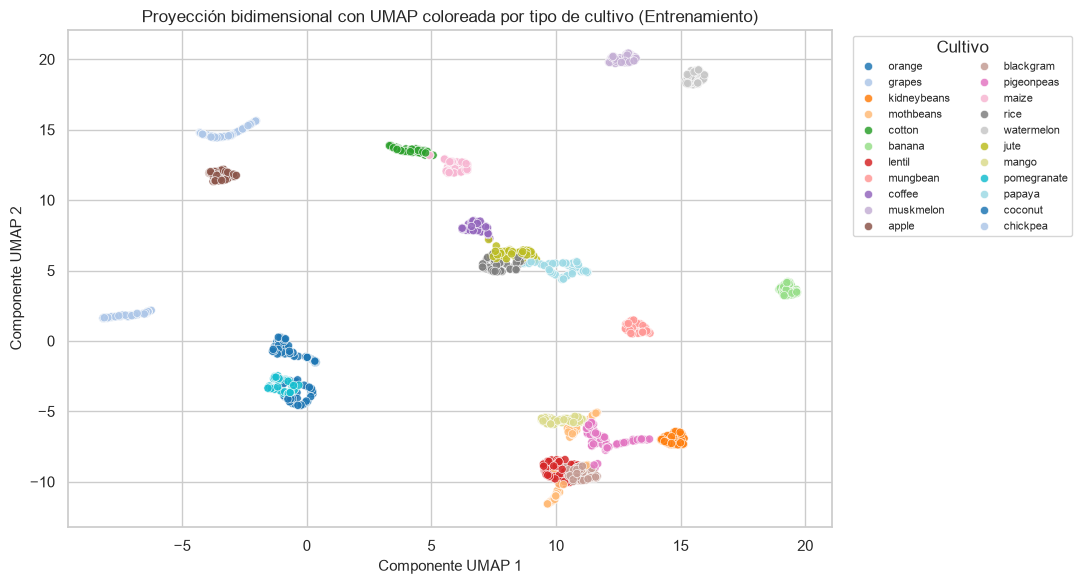

In [6]:
reductor_umap = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=RANDOM_STATE,
)
X_train_umap = reductor_umap.fit_transform(X_train_scaled)
X_test_umap = reductor_umap.transform(X_test_scaled)

df_umap_2d = pd.DataFrame(X_train_umap, columns=["UMAP1", "UMAP2"])
df_umap_2d["Cultivo"] = y_train.values

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_umap_2d,
    x="UMAP1",
    y="UMAP2",
    hue="Cultivo",
    palette="tab20",
    s=35,
    alpha=0.85,
)
plt.title("Proyección bidimensional con UMAP coloreada por tipo de cultivo (Entrenamiento)", fontsize=12)
plt.xlabel("Componente UMAP 1", fontsize=11)
plt.ylabel("Componente UMAP 2", fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8, title="Cultivo")
plt.tight_layout()
plt.show()

### 7. Evaluación de los dos mejores modelos sobre el espacio reducido con UMAP (Etapa 14)

Se entrenan los dos mejores clasificadores (**Perceptrón Multicapa** y **SVM RBF**) utilizando únicamente las 2 coordenadas generadas por UMAP (`X_train_umap`) y se evalúa su desempeño sobre la proyección del conjunto de prueba (`X_test_umap`), reduciendo de 7 a 2 variables.

Con solo 2 dimensiones para separar 22 cultivos, **SVM RBF + UMAP** alcanza un `Accuracy` de `0.9614` (`F1 Macro = 0.9611`) y **MLP + UMAP** obtiene un `Accuracy` de `0.9318` (`F1 Macro = 0.9294`), mostrando que el colector no lineal conserva gran parte de la estructura de clases.

In [7]:
resultados_umap: list[dict[str, Any]] = []
for nombre, modelo in crear_mejores_modelos().items():
    resultados_umap.append(
        evaluar_en_espacio(
            enfoque_nombre=f"UMAP: {nombre}",
            dimension_texto="Reducida (2 componentes UMAP)",
            modelo=modelo,
            X_tr=X_train_umap,
            X_te=X_test_umap,
        )
    )

df_resultados_umap = pd.DataFrame(resultados_umap)
display(df_resultados_umap)

,Enfoque / Modelo,Dimensión Original/Reducida,Accuracy,Error de Clasificación,Precision Macro,Recall Macro,F1 Macro
0,UMAP: Perceptrón Multicapa (MLP),Reducida (2 componentes UMAP),0.9318,0.0682,0.9406,0.9318,0.9294
1,UMAP: Support Vector Machine (SVM RBF),Reducida (2 componentes UMAP),0.9614,0.0386,0.9660,0.9614,0.9611


### 8. Comparación final integral del proyecto (Etapa 15)

Se integran en una sola tabla comparativa los resultados obtenidos sobre el conjunto de prueba (440 muestras) en los tres escenarios estudiados: los cinco modelos base con las 7 variables originales (Notebook 02), los dos mejores modelos entrenados con PCA (6 componentes) y los dos mejores modelos entrenados con UMAP (2 componentes).

La tabla presenta las columnas requeridas (`Enfoque / Modelo`, `Dimensión Original/Reducida`, `Accuracy`, `Error de Clasificación`, `Precision Macro`, `Recall Macro` y `F1 Macro`) para contrastar de forma directa el impacto de la reducción dimensional frente al desempeño predictivo.

In [8]:
columnas_finales: list[str] = [
    "Enfoque / Modelo",
    "Dimensión Original/Reducida",
    "Accuracy",
    "Error de Clasificación",
    "Precision Macro",
    "Recall Macro",
    "F1 Macro",
]

df_comparacion_final = pd.DataFrame(
    resultados_base_nb02 + resultados_pca + resultados_umap
)[columnas_finales]

display(df_comparacion_final)

,Enfoque / Modelo,Dimensión Original/Reducida,Accuracy,Error de Clasificación,Precision Macro,Recall Macro,F1 Macro
0,Base: Perceptrón Multicapa (MLP),Original (7 variables),0.9932,0.0068,0.9937,0.9932,0.9932
1,Base: Support Vector Machine (SVM RBF),Original (7 variables),0.9909,0.0091,0.9915,0.9909,0.9909
2,Base: Random Forest,Original (7 variables),0.9886,0.0114,0.9897,0.9886,0.9887
3,Base: Regresión Logística,Original (7 variables),0.9841,0.0159,0.9852,0.9841,0.9840
4,Base: K-Nearest Neighbors (KNN),Original (7 variables),0.9727,0.0273,0.9746,0.9727,0.9725
5,PCA: Perceptrón Multicapa (MLP),Reducida (6 componentes PCA),0.9886,0.0114,0.9889,0.9886,0.9886
6,PCA: Support Vector Machine (SVM RBF),Reducida (6 componentes PCA),0.9841,0.0159,0.9847,0.9841,0.9840
7,UMAP: Perceptrón Multicapa (MLP),Reducida (2 componentes UMAP),0.9318,0.0682,0.9406,0.9318,0.9294
8,UMAP: Support Vector Machine (SVM RBF),Reducida (2 componentes UMAP),0.9614,0.0386,0.9660,0.9614,0.9611


### 9. Conclusión técnica y discusión de resultados

A partir de la comparación integral entre el espacio original (7 variables) y las técnicas de reducción de dimensionalidad (PCA y UMAP), se concluye lo siguiente:

1. **Importancia de variables e interpretabilidad:** El análisis con Random Forest indica que `rainfall` (20.41%), `humidity` (20.33%), `K` (19.57%) y `P` (17.02%) aportan el 77.33% de la reducción de impureza de Gini. Los modelos base entrenados con las 7 variables originales obtienen el mayor desempeño global (**MLP** con `Accuracy = 0.9932` y `F1 Macro = 0.9932`; **SVM RBF** con `Accuracy = 0.9909` y `F1 Macro = 0.9909`), manteniendo además la interpretación directa de cada variable física y química del terreno.
2. **Desempeño con PCA (6 componentes):** Al proyectar linealmente a 6 componentes principales se conserva el **97.24%** de la varianza —eliminando la redundancia entre `P` y `K` ($r = 0.74$)— y se obtiene un rendimiento muy cercano al original (**MLP + PCA** con `Accuracy = 0.9886` y `F1 Macro = 0.9886`; **SVM RBF + PCA** con `Accuracy = 0.9841` y `F1 Macro = 0.9840`), a cambio de perder la interpretabilidad individual de las variables.
3. **Desempeño con UMAP (2 componentes):** UMAP logra comprimir las 7 variables en solo 2 coordenadas preservando la estructura topológica local y separando visualmente los 22 cultivos mucho mejor que el plano lineal `PC1 vs PC2`. En clasificación, **SVM RBF + UMAP** alcanza `Accuracy = 0.9614` (`F1 Macro = 0.9611`) y **MLP + UMAP** `Accuracy = 0.9318` (`F1 Macro = 0.9294`); por tanto, UMAP resulta ideal para visualización bidimensional de los cultivos, mientras que el espacio original de 7 variables (o 6 componentes con PCA) es la mejor elección para la predicción en producción.